In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    average_precision_score, 
    roc_auc_score
)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')


In [261]:
# Load dataset
df = pd.read_csv('../../data/paysim/paysim.csv')
print(f"Raw dataset shape: {df.shape}")
df.head()

Raw dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [262]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [263]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [264]:
pd.crosstab(df['type'], df['isFraud'])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [265]:
pd.crosstab(df['isFraud'], df['isFlaggedFraud'])

isFlaggedFraud,0,1
isFraud,,
0,6354407,0
1,8197,16


In [266]:
# Fraud onlu occurs in 'TRANSFER' and 'CASH_OUT'
df = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()

# Drop 4 features (task requirements) (f) and 'isFlaggedFraud' (ineffective)
df = df.drop(columns=['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud'])

# Encode type to 0/1
df['type'] = df['type'].map({'TRANSFER': 0, 'CASH_OUT': 1})

### FEATURE ENGINEERING - STEP

In [267]:
# Convert to hour of day(0-23)
df['hourOfDay'] = df['step'] % 24
hourly_fraud = pd.crosstab(df['hourOfDay'], df['isFraud'])
hourly_fraud['fraud_rate_pct'] = (df.groupby('hourOfDay')['isFraud'].mean() * 100).round(4)
print(hourly_fraud)

isFraud         0    1  fraud_rate_pct
hourOfDay                             
0           17914  300          1.6471
1            5647  358          5.9617
2            1550  372         19.3548
3             454  326         41.7949
4             238  274         53.5156
5             266  366         57.9114
6             546  358         39.6018
7            2214  328         12.9032
8            9934  368          3.5721
9          119687  341          0.2841
10         186649  375          0.2005
11         197916  324          0.1634
12         218222  339          0.1551
13         213560  346          0.1618
14         199009  353          0.1771
15         187795  341          0.1813
16         200561  345          0.1717
17         202453  353          0.1741
18         270338  343          0.1267
19         299591  342          0.1140
20         238549  340          0.1423
21          90579  347          0.3816
22          60813  351          0.5739
23          37711  323   

In [268]:
df['isNight'] = ((df['hourOfDay'] >= 0) & (df['hourOfDay'] <= 6)).astype(int)

In [269]:
# Convert to day of week
df['dayOfWeek'] = (df['step'] // 24) % 7
daily_fraud = pd.crosstab(df['dayOfWeek'], df['isFraud'])
daily_fraud['fraud_rate_pct'] = (df.groupby('dayOfWeek')['isFraud'].mean() * 100).round(4)
print(daily_fraud)

isFraud         0     1  fraud_rate_pct
dayOfWeek                              
0          664233  1309          0.1967
1          571725  1302          0.2272
2          372909  1454          0.3884
3          223018  1050          0.4686
4          161526  1062          0.6532
5          395442   996          0.2512
6          373343  1040          0.2778


### EDA - AMOUNT

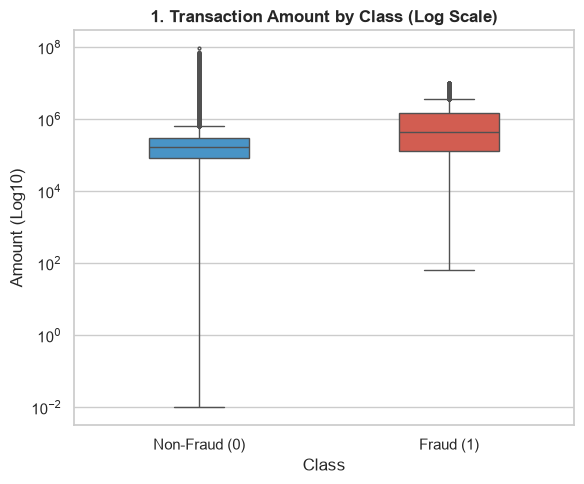

In [270]:
# Transaction Amount Distribution (Log Scale)
sns.set_theme(style="whitegrid")
palette = {0: '#3498db', 1: '#e74c3c'}

df_pos = df[df['amount'] > 0].copy()

plt.figure(figsize=(6, 5))
ax1 = sns.boxplot(
    data=df_pos, x='isFraud', y='amount', hue='isFraud',
    palette=palette, width=0.4, fliersize=2, legend=False
)
ax1.set_yscale('log')
ax1.set_title('1. Transaction Amount by Class (Log Scale)', fontweight='bold')
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['Non-Fraud (0)', 'Fraud (1)'])
ax1.set_xlabel('Class')
ax1.set_ylabel('Amount (Log10)')

plt.tight_layout()
plt.show()

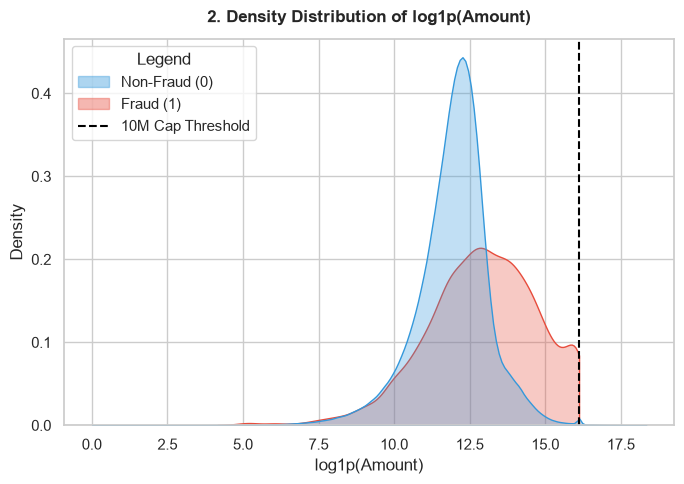

In [271]:
# Log-Transformed Amount Density 
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

df_pos['log_amount_temp'] = np.log1p(df_pos['amount'])

plt.figure(figsize=(7, 5))
ax2 = sns.kdeplot(
    data=df_pos, x='log_amount_temp', hue='isFraud',
    palette=palette, common_norm=False, fill=True, alpha=0.3,
    cut=0, legend=False  # cut=0 prevents curve from spilling past the actual max cap
)
ax2.axvline(np.log1p(10_000_000), color='black', linestyle='--', linewidth=1.5)


legend_elements_2 = [
    Patch(facecolor=palette[0], edgecolor=palette[0], alpha=0.4, label='Non-Fraud (0)'),
    Patch(facecolor=palette[1], edgecolor=palette[1], alpha=0.4, label='Fraud (1)'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=1.5, label='10M Cap Threshold')
]
ax2.legend(handles=legend_elements_2, title='Legend', loc='upper left', frameon=True)

ax2.set_title('2. Density Distribution of log1p(Amount)', fontweight='bold', pad=12)
ax2.set_xlabel('log1p(Amount)')
ax2.set_ylabel('Density')

plt.tight_layout()
plt.show()

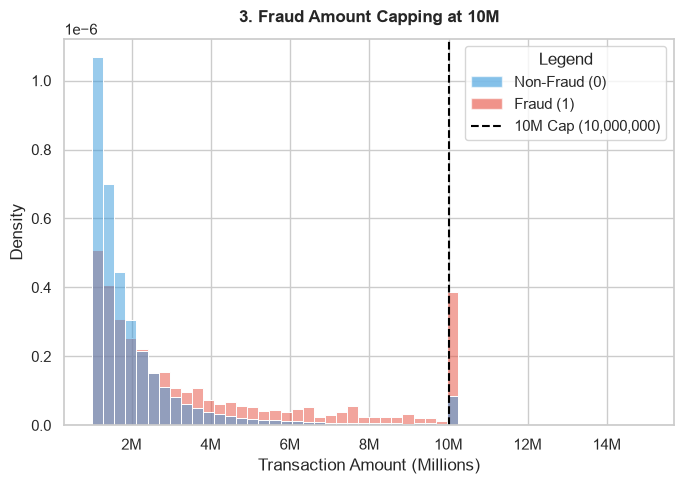

In [272]:
# %% [EDA 3.3] Fraud Capping Effect at 10M (1M - 15M Range)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

df_high = df[(df['amount'] >= 1_000_000) & (df['amount'] <= 15_000_000)]

plt.figure(figsize=(7, 5))
ax3 = sns.histplot(
    data=df_high, x='amount', hue='isFraud',
    palette=palette, bins=50, common_norm=False,
    stat='density', legend=False
)
ax3.axvline(10_000_000, color='black', linestyle='--', linewidth=1.5)


ax3.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))


legend_elements_3 = [
    Patch(facecolor=palette[0], edgecolor='white', alpha=0.6, label='Non-Fraud (0)'),
    Patch(facecolor=palette[1], edgecolor='white', alpha=0.6, label='Fraud (1)'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=1.5, label='10M Cap (10,000,000)')
]
ax3.legend(handles=legend_elements_3, title='Legend', loc='upper right', frameon=True)

ax3.set_title('3. Fraud Amount Capping at 10M', fontweight='bold', pad=12)
ax3.set_xlabel('Transaction Amount (Millions)')
ax3.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [273]:

df.groupby('isFraud')['amount'].describe().T

isFraud,0,1
count,2.762196e+06,8.213000e+03
mean,3.141155e+05,1.467967e+06
std,8.771441e+05,2.404253e+06
min,1.000000e-02,0.000000e+00
25%,8.290823e+04,1.270913e+05
50%,1.710345e+05,4.414234e+05
75%,3.059942e+05,1.517771e+06
max,9.244552e+07,1.000000e+07


### FEATURE ENGINEERING - AMOUNT

In [274]:


df['logAmount'] = np.log1p(df['amount'])

df['isCappedAmount'] = (df['amount'] == 10_000_000.0).astype(int)

df['isOverCap'] = (df['amount'] > 10_000_000.0).astype(int)

df['isZeroAmount'] = (df['amount'] == 0.0).astype(int)


### EDA - NAMEORIG, NAMEDEST

In [275]:
# 1. Check account prefixes (C = Customer, M = Merchant)
print("SENDER PREFIX DISTRIBUTION:")
print(df['nameOrig'].str[0].value_counts())

print("\nRECEIVER PREFIX DISTRIBUTION:")
print(df['nameDest'].str[0].value_counts())

SENDER PREFIX DISTRIBUTION:
nameOrig
C    2770409
Name: count, dtype: int64

RECEIVER PREFIX DISTRIBUTION:
nameDest
C    2770409
Name: count, dtype: int64


In [276]:

df_eda = df[['step', 'type', 'amount', 'nameOrig', 'nameDest', 'isFraud']].copy()

# Recipient transaction frequency
dest_counts = df_eda['nameDest'].value_counts()
df_eda['dest_tx_count'] = df_eda['nameDest'].map(dest_counts)

# Ratio of current amount to recipient's historical mean
dest_mean_amount = df_eda.groupby('nameDest')['amount'].transform('mean')
df_eda['amount_to_dest_mean_ratio'] = df_eda['amount'] / dest_mean_amount

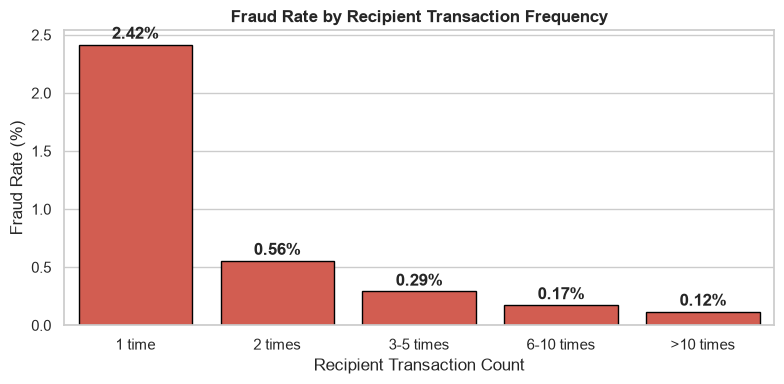

In [277]:
# Fraud rate by recipient transaction frequency
df_eda['dest_freq_bin'] = pd.cut(
    df_eda['dest_tx_count'],
    bins=[0, 1, 2, 5, 10, 1000],
    labels=['1 time', '2 times', '3-5 times', '6-10 times', '>10 times']
)

fraud_rate_q2 = df_eda.groupby('dest_freq_bin', observed=False)['isFraud'].mean() * 100

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=fraud_rate_q2.index, y=fraud_rate_q2.values, color='#e74c3c', edgecolor='black')
plt.title('Fraud Rate by Recipient Transaction Frequency', fontweight='bold')
plt.xlabel('Recipient Transaction Count')
plt.ylabel('Fraud Rate (%)')

# Data labels above bars
for i, v in enumerate(fraud_rate_q2.values):
    ax.text(i, v + 0.05, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

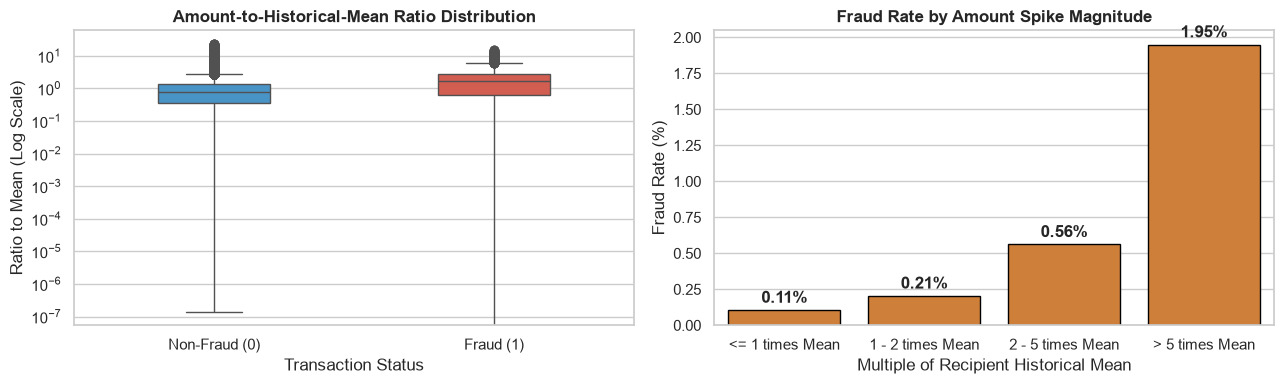

In [278]:

df_multi_dest = df_eda[df_eda['dest_tx_count'] > 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Chart: Boxplot of amount-to-mean ratio
sns.boxplot(
    data=df_multi_dest, x='isFraud', y='amount_to_dest_mean_ratio',
    palette=['#3498db', '#e74c3c'], width=0.4, ax=axes[0]
)
axes[0].set_yscale('log')
axes[0].set_title('Amount-to-Historical-Mean Ratio Distribution', fontweight='bold')
axes[0].set_xticklabels(['Non-Fraud (0)', 'Fraud (1)'])
axes[0].set_ylabel('Ratio to Mean (Log Scale)')
axes[0].set_xlabel('Transaction Status')

# Chart: Fraud rate by amount spike magnitude
df_multi_dest['spike_group'] = pd.cut(
    df_multi_dest['amount_to_dest_mean_ratio'],
    bins=[0, 1, 2, 5, 100],
    labels=['<= 1 times Mean', '1 - 2 times Mean', '2 - 5 times Mean', '> 5 times Mean']
)
fraud_rate_q4 = df_multi_dest.groupby('spike_group', observed=False)['isFraud'].mean() * 100

sns.barplot(
    x=fraud_rate_q4.index, y=fraud_rate_q4.values,
    color='#e67e22', edgecolor='black', ax=axes[1]
)
axes[1].set_title('Fraud Rate by Amount Spike Magnitude', fontweight='bold')
axes[1].set_xlabel('Multiple of Recipient Historical Mean')
axes[1].set_ylabel('Fraud Rate (%)')

# Data labels above bars
for i, v in enumerate(fraud_rate_q4.values):
    axes[1].text(i, v + 0.05, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [279]:
df

,step,type,amount,nameOrig,nameDest,isFraud,hourOfDay,isNight,dayOfWeek,logAmount,isCappedAmount,isOverCap,isZeroAmount
2,1,0,181.00,C1305486145,C553264065,1,1,1,0,5.204007,0,0,0
3,1,1,181.00,C840083671,C38997010,1,1,1,0,5.204007,0,0,0
15,1,1,229133.94,C905080434,C476402209,0,1,1,0,12.342066,0,0,0
19,1,0,215310.30,C1670993182,C1100439041,0,1,1,0,12.279840,0,0,0
24,1,0,311685.89,C1984094095,C932583850,0,1,1,0,12.649754,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,1,339682.13,C786484425,C776919290,1,23,0,2,12.735768,0,0,0
6362616,743,0,6311409.28,C1529008245,C1881841831,1,23,0,2,15.657870,0,0,0
6362617,743,1,6311409.28,C1162922333,C1365125890,1,23,0,2,15.657870,0,0,0
6362618,743,0,850002.52,C1685995037,C2080388513,1,23,0,2,13.652996,0,0,0


### FEATURE ENGINEERING - NAMEORIG, NAMEDEST

In [280]:
X = df.drop(columns=['isFraud'])
y = df['isFraud']

# Stratified split to keep fraud ratio consistent
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [281]:
train_dest_counts = X_train['nameDest'].value_counts()
train_orig_counts = X_train['nameOrig'].value_counts()

X_train['destTxCount'] = X_train['nameDest'].map(train_dest_counts)
X_test['destTxCount'] = X_test['nameDest'].map(train_dest_counts).fillna(0) + 1

X_train['origTxCount'] = X_train['nameOrig'].map(train_orig_counts)
X_test['origTxCount'] = X_test['nameOrig'].map(train_orig_counts).fillna(0) + 1

In [282]:
X_train['isSingleUseDest'] = (X_train['destTxCount'] == 1).astype(int)
X_test['isSingleUseDest'] = (X_test['destTxCount'] == 1).astype(int)

In [283]:
train_dest_mean_amt = X_train.groupby('nameDest')['amount'].mean()

X_train['destMeanAmount'] = X_train['nameDest'].map(train_dest_mean_amt)
X_test['destMeanAmount'] = X_test['nameDest'].map(train_dest_mean_amt).fillna(X_test['amount'])

X_train['amountToDestMeanRatio'] = X_train['amount'] / (X_train['destMeanAmount'] + 1e-5)
X_test['amountToDestMeanRatio'] = X_test['amount'] / (X_test['destMeanAmount'] + 1e-5)

In [284]:
cols_to_drop = ['step', 'amount', 'nameOrig', 'nameDest', 'destMeanAmount']
X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

In [285]:
num_cols = ['hourOfDay', 'dayOfWeek', 'logAmount', 'destTxCount', 'origTxCount', 'amountToDestMeanRatio']

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [286]:
log_reg = LogisticRegression(
    class_weight='balanced', 
    max_iter=1000, 
    random_state=42,
    n_jobs=-1
)

log_reg.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_

In [287]:
y_pred = log_reg.predict(X_test)

y_pred_proba = log_reg.predict_proba(X_test)[:, 1]

In [288]:

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

roc_auc = roc_auc_score(y_test, y_pred_proba)
auprc = average_precision_score(y_test, y_pred_proba)

print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"AUPRC Score (Primary Metric): {auprc:.4f}")

Confusion Matrix:
[[453448  98991]
 [   392   1251]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9991    0.8208    0.9012    552439
           1     0.0125    0.7614    0.0246      1643

    accuracy                         0.8206    554082
   macro avg     0.5058    0.7911    0.4629    554082
weighted avg     0.9962    0.8206    0.8986    554082

ROC-AUC Score: 0.8531
AUPRC Score (Primary Metric): 0.0373
